# QEC Memory Experiment With an Emulated Coprocessor

This tutorial walks you through the canonical quantum error correction (QEC) workload on a heterogeneous control system: a distance-3 surface-code memory experiment in which a coprocessor decodes syndrome measurements while the experiment is running, and the experiment applies a correction conditioned on the decoder's answer. You will declare the coprocessor and three data streams, write the sequence that streams syndromes as it runs, keep the qubits busy while the decoder computes, and branch on the result. Before you start, read [Quantum-Classical Algorithms and Heterogeneous Control](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/12_heterogeneous_control_system/concepts/index.html) for the high-level overview and [The Glass-Box Programming Model](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/12_heterogeneous_control_system/concepts/00_programming_model.html) for the DSL constructs used here.

Both the ZQCS and the coprocessor are **emulated**. The example illustrates the LabOne Q programming model; a real decoder running on a physical coprocessor is written in the native language of that platform rather than in Python. The LabOne Q side of the example is realistic, however.

**Limitations of the emulated setup**

The emulated models of the ZQCS and of the coprocessor are intentionally limited. Notably:

- LabOne Q's emulated ZQCS produces synthetic measurement data (`(42 + qudit_index) + result_index * 1j`). These are not real syndromes, so the decoder below is a stand-in rather than a real decoding algorithm.
- Responses are instantaneous and cannot steer the sequence: `match` on a coprocessor variable always takes the `case(0)` branch, and `do_until` runs its body exactly once. The structure of the experiment is exercised, the real-time behaviour is not.

The companion tutorial [The Emulated Coprocessor](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/12_heterogeneous_control_system/tutorials/02_emulated_coprocessor.html) covers the emulated coprocessor itself: how a kernel receives and emits packets, how the shape of the logged results follows the loop structure, and which violations of the contract the runtime reports.


A distance-3 surface-code memory experiment on 17 qubits: 9 data qubits and 8 ancilla qubits. A coprocessor runs the decoder. We start by defining a [DeviceSetup](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/00_device_setup/concepts/index.html) containing the control signals for all 17 qubits. We also instantiate the emulated coprocessor.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from laboneq.dsl.experiment.builtins import *
from laboneq.simple import *
from zhinst_zqcs.emulation import EmulatedCoprocessorKernel, add_emulated_coprocessor

descriptor = """\
instruments:
  ZQCS:
  - address: http://DEV_ZQCS
    uid: zqcs
connections:
  zqcs:
    # Qubit 1
    - rf_signal: q1/flux
      ports: ["1:11:3:1"]
    - iq_signal: q1/drive
      ports: ["1:3:1:1"]
    - iq_signal: q1/measure
      ports: ["1:3:3:1"]
    - acquire_signal: q1/acquire
      ports: ["1:3:3:3"]

    # Qubit 2
    - rf_signal: q2/flux
      ports: ["1:11:3:2"]
    - iq_signal: q2/drive
      ports: ["1:3:1:2"]
    - iq_signal: q2/measure
      ports: ["1:3:3:1"]
    - acquire_signal: q2/acquire
      ports: ["1:3:3:3"]

    # Qubit 3
    - rf_signal: q3/flux
      ports: ["1:11:3:3"]
    - iq_signal: q3/drive
      ports: ["1:3:1:3"]
    - iq_signal: q3/measure
      ports: ["1:3:3:1"]
    - acquire_signal: q3/acquire
      ports: ["1:3:3:3"]

    # Qubit 4
    - rf_signal: q4/flux
      ports: ["1:11:3:4"]
    - iq_signal: q4/drive
      ports: ["1:3:1:4"]
    - iq_signal: q4/measure
      ports: ["1:3:3:1"]
    - acquire_signal: q4/acquire
      ports: ["1:3:3:3"]

    # Qubit 5
    - rf_signal: q5/flux
      ports: ["1:11:3:5"]
    - iq_signal: q5/drive
      ports: ["1:3:1:5"]
    - iq_signal: q5/measure
      ports: ["1:3:3:2"]
    - acquire_signal: q5/acquire
      ports: ["1:3:3:4"]

    # Qubit 6
    - rf_signal: q6/flux
      ports: ["1:11:3:6"]
    - iq_signal: q6/drive
      ports: ["1:3:1:6"]
    - iq_signal: q6/measure
      ports: ["1:3:3:2"]
    - acquire_signal: q6/acquire
      ports: ["1:3:3:4"]

    # Qubit 7
    - rf_signal: q7/flux
      ports: ["1:11:3:7"]
    - iq_signal: q7/drive
      ports: ["1:3:1:7"]
    - iq_signal: q7/measure
      ports: ["1:3:3:2"]
    - acquire_signal: q7/acquire
      ports: ["1:3:3:4"]

    # Qubit 8
    - rf_signal: q8/flux
      ports: ["1:11:4:1"]
    - iq_signal: q8/drive
      ports: ["1:3:2:1"]
    - iq_signal: q8/measure
      ports: ["1:3:3:2"]
    - acquire_signal: q8/acquire
      ports: ["1:3:3:4"]

    # Qubit 9
    - rf_signal: q9/flux
      ports: ["1:11:4:2"]
    - iq_signal: q9/drive
      ports: ["1:3:2:2"]
    - iq_signal: q9/measure
      ports: ["1:3:4:1"]
    - acquire_signal: q9/acquire
      ports: ["1:3:4:3"]

    # Qubit 10
    - rf_signal: q10/flux
      ports: ["1:11:4:3"]
    - iq_signal: q10/drive
      ports: ["1:3:2:3"]
    - iq_signal: q10/measure
      ports: ["1:3:4:1"]
    - acquire_signal: q10/acquire
      ports: ["1:3:4:3"]

    # Qubit 11
    - rf_signal: q11/flux
      ports: ["1:11:4:4"]
    - iq_signal: q11/drive
      ports: ["1:3:2:4"]
    - iq_signal: q11/measure
      ports: ["1:3:4:1"]
    - acquire_signal: q11/acquire
      ports: ["1:3:4:3"]

    # Qubit 12
    - rf_signal: q12/flux
      ports: ["1:11:4:5"]
    - iq_signal: q12/drive
      ports: ["1:3:2:5"]
    - iq_signal: q12/measure
      ports: ["1:3:4:1"]
    - acquire_signal: q12/acquire
      ports: ["1:3:4:3"]

    # Qubit 13
    - rf_signal: q13/flux
      ports: ["1:11:4:6"]
    - iq_signal: q13/drive
      ports: ["1:3:2:6"]
    - iq_signal: q13/measure
      ports: ["1:3:4:2"]
    - acquire_signal: q13/acquire
      ports: ["1:3:4:4"]

    # Qubit 14
    - rf_signal: q14/flux
      ports: ["1:11:4:7"]
    - iq_signal: q14/drive
      ports: ["1:3:2:7"]
    - iq_signal: q14/measure
      ports: ["1:3:4:2"]
    - acquire_signal: q14/acquire
      ports: ["1:3:4:4"]

    # Qubit 15
    - rf_signal: q15/flux
      ports: ["1:11:5:1"]
    - iq_signal: q15/drive
      ports: ["1:2:1:1"]
    - iq_signal: q15/measure
      ports: ["1:3:4:2"]
    - acquire_signal: q15/acquire
      ports: ["1:3:4:4"]

    # Qubit 16
    - rf_signal: q16/flux
      ports: ["1:11:5:2"]
    - iq_signal: q16/drive
      ports: ["1:2:1:2"]
    - iq_signal: q16/measure
      ports: ["1:3:4:2"]
    - acquire_signal: q16/acquire
      ports: ["1:3:4:4"]

    # Qubit 17
    - rf_signal: q17/flux
      ports: ["1:11:5:3"]
    - iq_signal: q17/drive
      ports: ["1:2:1:3"]
    - iq_signal: q17/measure
      ports: ["1:3:5:1"]
    - acquire_signal: q17/acquire
      ports: ["1:3:5:3"]
"""

setup = DeviceSetup.from_descriptor(
    yaml_text=descriptor, server_host="localhost", server_port=-1
)
emulated_coprocessor = add_emulated_coprocessor(setup)

session = Session(setup)
session.connect(do_emulation=True)

[2026.10.15 12:50:53.416] INFO    Logging initialized from [Default inline config in laboneq.laboneq_logging] logdir is C:\LabOne Q\laboneq\examples\09_heterogeneous_control_system\laboneq_output\log
[2026.10.15 12:50:53.430] INFO    VERSION: laboneq 26.10.0.dev0
[2026.10.15 12:50:53.438] INFO    ZQCS:http://dev_zqcs: Fetched the setup description from http://DEV_ZQCS, SCM version <emulated run>, Session version <emulated run>


## The Experiment

A distance-3 surface-code memory experiment consists of a series of stabilizer measurements and a decoding process that keeps track of the error syndromes reported by the stabilizers. A coprocessor runs the decoder. In each stabilizer round the experiment measures all 8 ancillas and streams the syndrome to the decoder; at the end of the main phase it measures the 9 data qubits and streams those results too. The decoder combines everything it has received and responds with a single flag that tells the experiment whether to apply a corrective logical Hadamard gate.

The interesting part is the timing. Decoding takes longer than a stabilizer round, and the experiment does not know in advance when the decoder will answer. Instead of idling, it keeps playing stabilizer rounds – tail rounds – until the flag arrives, then branches on it. Each iteration therefore has four phases:

1. **Initial stabilizer rounds.** Run the syndrome-extraction circuit, measure all ancillas, send the syndrome packet to the decoder.
2. **Final data readout.** Measure all 9 data qubits and send the results to the decoder.
3. **Tail rounds.** Keep running stabilizer rounds and streaming syndromes until the decoder responds. The decoder decides when to answer; the experiment only sets an upper limit on the waiting time, after which it stops with an error.
4. **Conditional correction.** Branch on the decoder's flag and, if required, apply a logical correction gate to the data qubits; in our example, a logical Hadamard gate.

The decoder knows the circuit statically: it knows the schedule of syndrome rounds, and it knows that a data-qubit readout ends the main phase. No round counters or phase markers travel in the packets. The figure below shows how the four phases interleave with the decoder in one iteration.

<figure>
<img src="qec_decoding_flow.svg" style="width:100%">
<figcaption align = "center"> Figure 1: One iteration of the QEC memory experiment. Each stabilizer round streams one syndrome packet to the decoder while the sequence keeps running. After the data readout ends the main phase, the experiment plays tail rounds instead of idling; the decoder's flag exits the <code>do_until(is_live(...))</code> loop, and <code>match</code> steers the conditional correction. </figcaption>
</figure>

The supported types, directions, and binding methods of schema fields are listed in the [Struct Schema Reference](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/12_heterogeneous_control_system/concepts/01_struct_reference.html), and the [Variables Reference](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/12_heterogeneous_control_system/concepts/02_variables_reference.html) gives an overview of LabOne Q `Variables`.


In [2]:
# --- Distance-3 surface code: 9 data + 8 ancilla qubits -------------
N_DATA = 9
N_ANC = 8
N_INITIAL_ROUNDS = 10  # stabilizer rounds before the data readout
MAX_TAIL_ROUNDS = 10  # upper limit on the wait for the decoder
N_REPETITIONS = 20  # experiment repetitions

DATA_QUBITS = [f"data_{i}" for i in range(N_DATA)]
ANC_QUBITS = [f"anc_{i}" for i in range(N_ANC)]

# Acquisition handles: one per qubit, reused every round
ANC_HANDLES_IR = [f"{q}_initial_rounds" for q in ANC_QUBITS]
ANC_HANDLES_TR = [f"{q}_tail_rounds" for q in ANC_QUBITS]
DATA_HANDLES = DATA_QUBITS

# Experiment signals: a drive and a flux line for every qubit, and a
# measure/acquire line pair for every qubit
SIGNALS = (
    [f"{q}_drive" for q in DATA_QUBITS + ANC_QUBITS]
    + [f"{q}_flux" for q in DATA_QUBITS + ANC_QUBITS]
    + [f"{q}_measure" for q in DATA_QUBITS + ANC_QUBITS]
    + [f"{q}_acquire" for q in DATA_QUBITS + ANC_QUBITS]
)

x90_pulse = pulse_library.drag(length=32e-9, amplitude=0.4, beta=0.2)
hadamard_pulse = pulse_library.drag(length=32e-9, amplitude=0.8, beta=0.2)
entangle_pulse = pulse_library.gaussian_square(length=120e-9, amplitude=0.6)

# Up to three qubits share one measure port in the descriptor above, and
# pulses that overlap on a port add up. Keep the amplitude below 1/3 so the
# summed readout waveform stays within the output range.
measure_pulse = pulse_library.gaussian_square(length=1.2e-6, amplitude=0.3)
readout_kernel = pulse_library.const(length=1e-6, amplitude=1.0)

RELAX_TIME = 2e-6  # passive ancilla reset

In [3]:
def play_stabilizer_round():
    """One syndrome-extraction round (schematic).

    Basis change on the X-type ancillas, four entangling layers with the
    neighboring data qubits, basis change back.
    """
    with section(name="stabilizer_round"):
        for i in range(4):  # X-type ancillas
            play(f"anc_{i}_drive", x90_pulse)
        for _layer in range(4):  # entangling layers
            for q in ANC_QUBITS:
                play(f"{q}_flux", entangle_pulse)
        for i in range(4):
            play(f"anc_{i}_drive", x90_pulse)


def measure_ancillas(handle):
    """Read out all 8 ancillas into their acquisition handles."""
    with section(name="ancilla_readout"):
        for q in ANC_QUBITS:
            play(f"{q}_measure", measure_pulse)
            acquire(f"{q}_acquire", handle=f"{q}_{handle}", kernel=readout_kernel)
            delay(signal=f"{q}_acquire", time=1.2e-6)


def measure_data_qubits():
    """Read out all 9 data qubits into their acquisition handles."""
    with section(name="data_qubit_readout"):
        for q in DATA_QUBITS:
            play(f"{q}_measure", measure_pulse)
            acquire(f"{q}_acquire", handle=q, kernel=readout_kernel)
            delay(signal=f"{q}_acquire", time=1.2e-6)


def reset_ancillas():
    """Passive reset: let the ancillas relax."""
    with section(name="ancilla_reset"):
        for q in ANC_QUBITS:
            delay(f"{q}_drive", RELAX_TIME)


@experiment(signals=SIGNALS, coprocessors=["decoder"])
def surface_code_memory():
    # DECLARING THE STREAMS
    # Syndrome data: 8 ancilla measurements per round.
    syndrome_initial_stream = register_stream(
        dst="decoder",
        schema=Struct(measurement=IqDataPacked),
        uid="syndromes_initial_rounds",
    )
    syndrome_initial_stream.fields["measurement"].set_handles(ANC_HANDLES_IR)

    syndrome_tail_stream = register_stream(
        dst="decoder",
        schema=Struct(measurement=IqDataPacked),
        uid="syndromes_tail_rounds",
    )
    syndrome_tail_stream.fields["measurement"].set_handles(ANC_HANDLES_TR)

    # Final data-qubit readout: 9 measurements, sent once per iteration.
    data_readout_stream = register_stream(
        dst="decoder",
        schema=Struct(measurement=IqDataPacked),
        uid="data_readout",
    )
    data_readout_stream.fields["measurement"].set_handles(DATA_HANDLES)

    # The decoder answers with a single integer flag. Bind it to a Variable
    # and log it, so that every response lands in the results.
    decoder_response = register_stream(
        src="decoder",
        schema=Struct(flag=Int32),
        uid="decoder_response",
    )
    correction_flag = decoder_response.fields["flag"].as_variable(name="flag")
    correction_flag.log(handle="corrections")  # one update per iteration

    # CREATING THE PULSE SEQUENCE
    with acquire_loop_rt(
        count=N_REPETITIONS,
        uid="experiment_repetitions",
        averaging_mode=AveragingMode.SINGLE_SHOT,
        acquisition_type=AcquisitionType.INTEGRATION,
    ):
        # Ready for this iteration's correction flag.
        mark_stale(correction_flag)

        # --- Phase 1: initial stabilizer rounds ---
        with section(uid="initial_rounds"):
            with for_each(range(N_INITIAL_ROUNDS), uid="rounds", axis_name="round"):
                with section(name="one_round"):
                    play_stabilizer_round()

                    # The ancilla handles are bound to syndrome_stream, so
                    # each acquire feeds the stream automatically.
                    measure_ancillas(handle="initial_rounds")

                    # Commit this round's packet: these eight measurements
                    # form one unit of work for the decoder.
                    send(syndrome_initial_stream)

                    reset_ancillas()

        # --- Phase 2: final data-qubit readout ---
        with section(uid="data_readout", play_after="initial_rounds"):
            measure_data_qubits()
            # Tells the decoder that the main phase is over.
            send(data_readout_stream)

        # --- Phase 3: keep the qubits busy until the decoder answers ---
        with section(uid="tail_rounds", play_after="data_readout"):
            with do_until(is_live(correction_flag), max_count=MAX_TAIL_ROUNDS):
                play_stabilizer_round()
                measure_ancillas(handle="tail_rounds")
                send(syndrome_tail_stream)
                reset_ancillas()

        # --- Phase 4: conditional correction ---
        with match(correction_flag, play_after="tail_rounds"):
            with case(0):
                pass  # no correction
            with case(1):
                with section(name="logical_hadamard"):
                    for q in DATA_QUBITS:
                        play(f"{q}_drive", hadamard_pulse)

## The Decoder (Emulated Coprocessor)

The experiment definition is only half of the deal. We also have to implement the logic that runs on the coprocessor. This example uses an emulated coprocessor, where the compute kernel is written in Python.

The kernel mirrors the structure of one iteration: it receives one syndrome packet per initial round, then the final data-qubit readout, and then emits a single flag. A real decoder would run a matching algorithm over the syndrome history; here we derive a deterministic stand-in value from the emulated data so that the logged flag varies from iteration to iteration.

Note that the emulated coprocessor expects exactly one emitted value per `mark_stale`. The kernel emits immediately after the data readout arrives, and parks on the next `recv()` afterwards.


In [4]:
class SurfaceCodeDecoder(EmulatedCoprocessorKernel):
    """Stand-in decoder: consumes one iteration's syndromes, then answers once."""

    async def run(self, ctx):
        while True:
            # One syndrome packet per initial stabilizer round.
            syndromes = [
                await ctx.streams["syndromes_initial_rounds"].recv()
                for _ in range(N_INITIAL_ROUNDS)
            ]

            # The data-qubit readout closes the main phase of this iteration.
            data_readout = await ctx.streams["data_readout"].recv()

            # The experiment keeps streaming syndromes from the tail rounds
            # while it waits. Fold the first of them into the decision, so
            # that the answer lands while the acceptance window is open.
            tail = await ctx.streams["syndromes_tail_rounds"].recv()

            # A real decoder would infer the error chain from the syndrome
            # history. We just fold the emulated values into a 0/1 flag.
            weight = sum(
                abs(value)
                for packet in [*syndromes, data_readout, tail]
                for value in packet.measurement.values()
            )
            ctx.streams["decoder_response"].emit(flag=int(weight) % 2)

## Compile and run the experiment

We map the experiment signals to logical signals in the DeviceSetup [as usual](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/05_experiment/concepts/index.html#experimental-signal-map). In addition, we map the experiment's `decoder` label to the emulated coprocessor. You can find all available coprocessors in `setup.coprocessors`; physical coprocessors would be listed there too.

After compiling, we attach the `SurfaceCodeDecoder` class as the payload of the emulated coprocessor. We could also have done this in the experiment definition with `set_coprocessor_payload`, see [LabOne Q DSL Constructs for Classical Processing](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/12_heterogeneous_control_system/concepts/00_programming_model.html#labone-q-dsl-constructs-for-classical-processing).


In [5]:
# Create the experiment
exp = surface_code_memory()

# Map the experiment signals to logical signals in the DeviceSetup.
# The surface-code roles are laid out over the 17 qubits of the descriptor.
qubit_of = {
    "anc_0": "q1",
    "data_0": "q2",
    "data_1": "q3",
    "anc_1": "q4",
    "data_2": "q5",
    "anc_2": "q6",
    "data_3": "q7",
    "anc_3": "q8",
    "data_4": "q9",
    "anc_4": "q10",
    "data_5": "q11",
    "anc_5": "q12",
    "data_6": "q13",
    "anc_6": "q14",
    "data_7": "q15",
    "data_8": "q16",
    "anc_7": "q17",
}
for role, qubit in qubit_of.items():
    for line in ["drive", "flux", "measure", "acquire"]:
        exp.map_signal(
            f"{role}_{line}",
            setup.logical_signal_groups[qubit].logical_signals[line],
        )

# Map the experiment decoder to the emulated coprocessor
exp.map_coprocessor("decoder", emulated_coprocessor)

# Compile the experiment
compiled = session.compile(exp)
# Upload the payload to the emulated coprocessor
compiled.set_coprocessor_payload("decoder", b"__main__:SurfaceCodeDecoder")

# Run the experiment
results = session.run(compiled)

[2026.10.15 12:50:53.882] INFO    Starting LabOne Q Compiler run...
[2026.10.15 12:50:53.891] INFO    Schedule completed. [0.003 s]
[2026.10.15 12:50:53.926] INFO    Code generation completed. [0.032 s]
[2026.10.15 12:50:53.931] INFO    Completed compilation step 1 of 1. [0.042 s]
[2026.10.15 12:50:53.934] INFO    Finished LabOne Q Compiler run.
[2026.10.15 12:50:53.947] INFO    Starting near-time execution...
[2026.10.15 12:50:56.390] INFO    Finished near-time execution.


## Inspecting the Logged Variables in the Results

In the results we can trace the decisions taken by the decoder, next to the acquired measurement data. The logged variable is shaped by the loops enclosing its `mark_stale`, so there is one flag per experiment repetition. The ancilla handles were acquired inside the round loop, so they carry one value per repetition and round.


In [6]:
corrections = results.variable_results["corrections"]
syndrome_q0 = results.acquired_results["anc_0_initial_rounds"]
data_q0 = results.acquired_results["data_0"]

print("corrections :", corrections.data.shape, "axes:", corrections.axis_name)
print("anc_0 (initial):", syndrome_q0.data.shape, "axes:", syndrome_q0.axis_name)
print("data_0      :", data_q0.data.shape, "axes:", data_q0.axis_name)
print("all flags valid:", bool(corrections.valid.all()))
print("flags       :", corrections.data)

corrections : (20,) axes: ['experiment_repetitions']
anc_0 (initial): (20, 10) axes: ['experiment_repetitions', 'round']
data_0      : (20,) axes: ['experiment_repetitions']
all flags valid: True
flags       : [0 1 1 0 1 0 1 1 0 0 1 0 1 0 1 1 1 0 1 1]


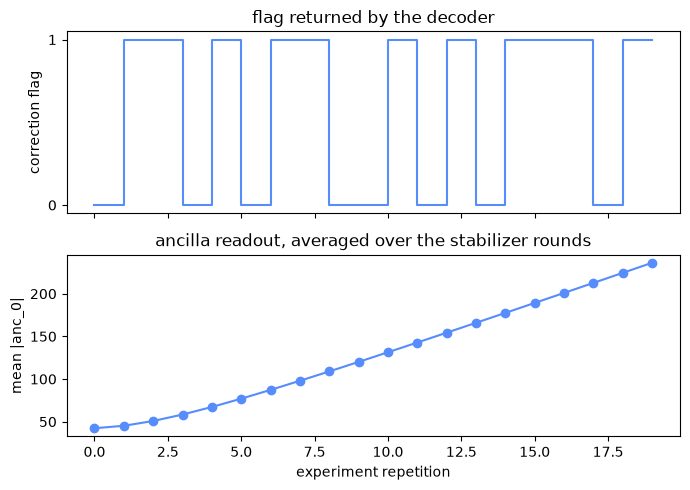

In [7]:
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(7, 5))

top.step(np.arange(N_REPETITIONS), corrections.data, where="post")
top.set_ylabel("correction flag")
top.set_yticks([0, 1])
top.set_title("flag returned by the decoder")

bottom.plot(
    np.arange(N_REPETITIONS),
    np.abs(syndrome_q0.data).mean(axis=1),
    marker="o",
)
bottom.set_xlabel("experiment repetition")
bottom.set_ylabel("mean |anc_0|")
bottom.set_title("ancilla readout, averaged over the stabilizer rounds")

fig.tight_layout()
plt.show()

## Where to Go from Here

In this experiment the decoder's response steers a branch, and the sequence fills the unknown waiting time with tail rounds. The other canonical quantum-classical workload inverts both choices: the coprocessor's response updates a pulse, and the experiment waits for it with a fixed time budget. The [Fast Rabi Tune-Up](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/12_heterogeneous_control_system/tutorials/00_bayesian_rabi_tuneup_emulation.html) notebook shows that pattern end to end.

For the kernel side of the emulation – `recv`, `emit`, the shape of the logged results, and the contract violations the runtime reports – see [The Emulated Coprocessor](https://docs.zhinst.com/labone_q_user_manual/core/functionality_and_concepts/12_heterogeneous_control_system/tutorials/02_emulated_coprocessor.html).
